**09 · Barrido grado–número de puntos (grid configurable 6×6, 8×8, etc.)**

Este cuaderno genera exactamente el tipo de figura que mencionaste: una retícula donde cada celda muestra la reconstrucción/estimación al variar simultáneamente el **grado** y el **número de puntos**. El ejemplo por defecto usa una figura 2D para que la lectura sea inmediata, pero puedes adaptarlo a otras formas o a una superficie 3D.

In [2]:
from pathlib import Path
import sys, subprocess, os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/'benchmarks'/'common.py').exists() and (p/'pyproject.toml').exists()), None)
if ROOT is None:
    raise RuntimeError("Abre Jupyter desde la raíz de point-field o una subcarpeta del repositorio.")
sys.path.insert(0, str(ROOT/'benchmarks'))
OUT = ROOT/'runs'/'tesis_figuras'
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'font.size': 10, 'axes.titlesize': 11, 'figure.dpi': 120, 'savefig.dpi': 300, 'pdf.fonttype': 42})
COLORS = ['#21618c','#c65036','#63933e','#8b65a5','#c49a38','#458e91','#d16c9f','#555555']
def save(fig, name):
    for ext in ('pdf','png'):
        fig.savefig(OUT/f'{name}.{ext}', bbox_inches='tight', facecolor='white')
    plt.show(); plt.close(fig)
def points(ax, X, y=None, s=6):
    X=np.asarray(X)
    if y is None:
        if X.shape[1]==2: ax.scatter(X[:,0],X[:,1],s=s,c=COLORS[0],linewidths=0)
        else: ax.scatter(X[:,0],X[:,1],X[:,2],s=s,c=COLORS[0],linewidths=0)
    else:
        labs=np.unique(y)
        for j,c in enumerate(labs):
            col='#b9b9b9' if c==-1 else COLORS[j%len(COLORS)]
            m=(y==c)
            if X.shape[1]==2: ax.scatter(X[m,0],X[m,1],s=s,c=col,linewidths=0)
            else: ax.scatter(X[m,0],X[m,1],X[m,2],s=s,c=col,linewidths=0)
    ax.set_xticks([]); ax.set_yticks([])
    if X.shape[1]==2:
        ax.set_aspect('equal', adjustable='box')
    else:
        ax.set_zticks([]); ax.set_box_aspect((1,1,1)); ax.view_init(elev=23, azim=35)
def run_script(name, *args):
    subprocess.run([sys.executable, str(ROOT/'benchmarks'/name), *map(str,args)], cwd=ROOT, check=True)
print('Repositorio:', ROOT, 'Salidas:', OUT)
try:
    commit=subprocess.check_output(['git','rev-parse','HEAD'],cwd=ROOT,text=True).strip()
except Exception:
    commit='No disponible'
print('Commit:', commit)


Repositorio: /home/icantu24/Documents/PEF-CD/point-field Salidas: /home/icantu24/Documents/PEF-CD/point-field/runs/tesis_figuras
Commit: 88445aa61ca2a66afcc53a931cf0927232ef232f


**1. Configuración.** Ajusta `DEGREES` y `NPOINTS` hasta obtener el tamaño de retícula que quieras. Si quieres una 8×8, define ocho grados y ocho tamaños.

In [3]:
from pointfield.geometry.shapes2d import Annulus, Rectangle, Ellipse
from pointfield.learning import ChristoffelDarboux

SHAPE_NAME = 'Annulus'
SHAPE = Annulus(0.5, 1.0)
DEGREES = [1, 2, 4, 8, 16, 32]  # ejemplo; añade más si quieres 8 filas
NPOINTS = [100, 200, 500, 1000, 2000, 4000]  # ejemplo; añade más si quieres 8 columnas
SEED = 100
GRID = 180
THRESHOLD = 'p95'  # percentil 95 del entrenamiento
print('Forma:', SHAPE_NAME, 'grados:', DEGREES, 'puntos:', NPOINTS)


Forma: Annulus grados: [1, 2, 4, 8, 16, 32] puntos: [100, 200, 500, 1000, 2000, 4000]


**2. Generación de la retícula.** Cada celda superpone puntos de entrenamiento, campo reescalado y contorno de aceptación. Para tesis, esta figura funciona mejor si se usa una escala visual común por fila o por toda la retícula.

Grado= 1 | N=  100 | Monomios=   3
Grado= 1 | N=  200 | Monomios=   3
Grado= 1 | N=  500 | Monomios=   3
Grado= 1 | N= 1000 | Monomios=   3
Grado= 1 | N= 2000 | Monomios=   3
Grado= 1 | N= 4000 | Monomios=   3
Grado= 1 | N= 8000 | Monomios=   3
Grado= 1 | N=16000 | Monomios=   3
Grado= 2 | N=  100 | Monomios=   6
Grado= 2 | N=  200 | Monomios=   6
Grado= 2 | N=  500 | Monomios=   6
Grado= 2 | N= 1000 | Monomios=   6
Grado= 2 | N= 2000 | Monomios=   6
Grado= 2 | N= 4000 | Monomios=   6
Grado= 2 | N= 8000 | Monomios=   6
Grado= 2 | N=16000 | Monomios=   6
Grado= 4 | N=  100 | Monomios=  15
Grado= 4 | N=  200 | Monomios=  15
Grado= 4 | N=  500 | Monomios=  15
Grado= 4 | N= 1000 | Monomios=  15
Grado= 4 | N= 2000 | Monomios=  15
Grado= 4 | N= 4000 | Monomios=  15
Grado= 4 | N= 8000 | Monomios=  15
Grado= 4 | N=16000 | Monomios=  15
Grado= 6 | N=  100 | Monomios=  28
Grado= 6 | N=  200 | Monomios=  28
Grado= 6 | N=  500 | Monomios=  28
Grado= 6 | N= 1000 | Monomios=  28
Grado= 6 | N= 2000 |

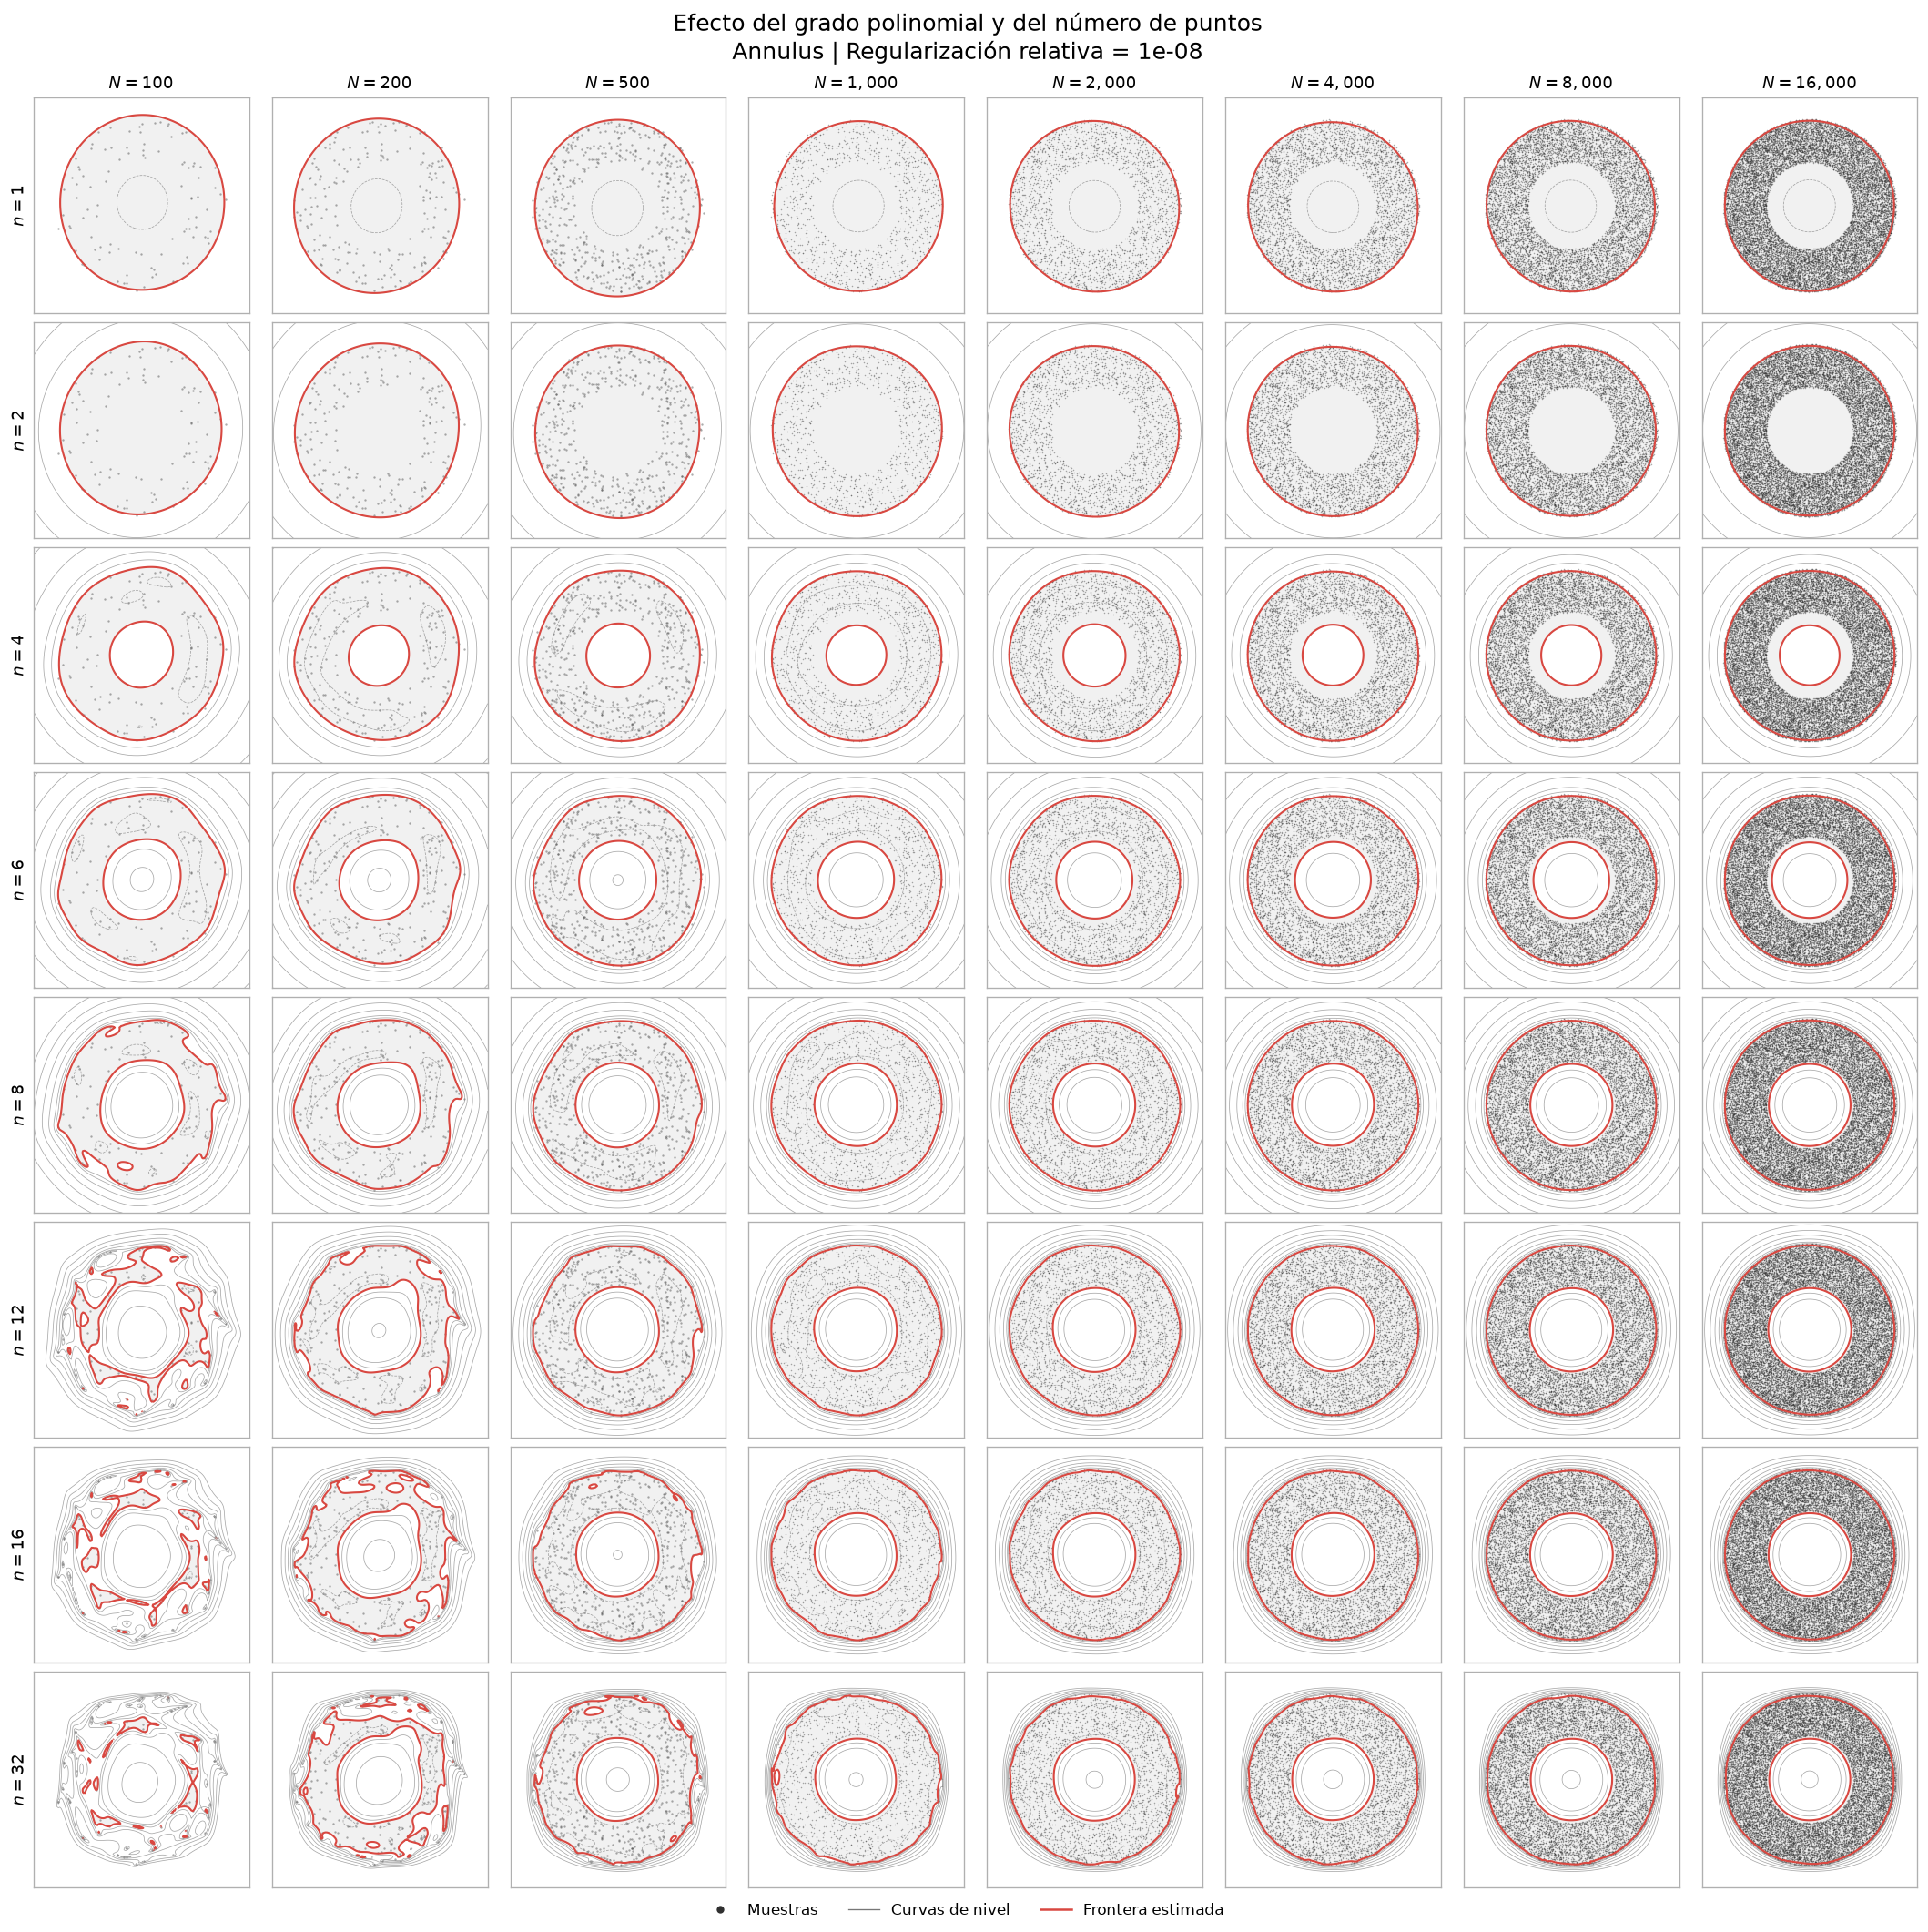

,degree,n_points,basis_size,N_per_basis,necessarily_rank_deficient,cond_M,cond_regularized,effective_dof,regularization,threshold,fit_time_s,eval_time_s,status
0,1,100,3,33.333333,False,3.442427e+00,3.442427e+00,3.000000,5.410476e-09,4.096819,0.000264,0.015141,OK
1,1,200,3,66.666667,False,3.430420e+00,3.430420e+00,3.000000,5.413771e-09,4.099963,0.000209,0.006650,OK
2,1,500,3,166.666667,False,3.427358e+00,3.427358e+00,3.000000,5.426304e-09,4.118666,0.000197,0.001014,OK
3,1,1000,3,333.333333,False,3.232177e+00,3.232177e+00,3.000000,5.427628e-09,4.054230,0.000203,0.001192,OK
4,1,2000,3,666.666667,False,3.220592e+00,3.220592e+00,3.000000,5.447189e-09,4.046716,0.000218,0.009635,OK
...,...,...,...,...,...,...,...,...,...,...,...,...,...
59,32,1000,561,1.782531,False,7.358302e+25,2.228626e+10,141.560541,6.007059e-11,428.262768,0.132512,0.754847,OK
60,32,2000,561,3.565062,False,2.241603e+27,2.177842e+10,143.517822,6.219905e-11,389.138393,0.132443,0.819228,OK
61,32,4000,561,7.130125,False,1.432050e+26,2.229379e+10,144.276592,6.011619e-11,381.770857,0.202932,0.941314,OK
62,32,8000,561,14.260250,False,4.537742e+26,2.256910e+10,144.683156,5.904037e-11,377.831883,0.237398,0.744948,OK


In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from math import comb
from time import perf_counter
from matplotlib.lines import Line2D
from pointfield.learning import ChristoffelDarboux

# ============================================================
# 1. CONFIGURACIÓN EXPERIMENTAL
# ============================================================

DEGREES = [1, 2, 4, 6, 8, 12, 16, 32]

NPOINTS = [
    100, 200, 500, 1000,
    2000, 4000, 8000, 16000
]

SEED = 100
GRID = 150
REG = 1e-8
BATCH_SIZE = 2048
PERCENTILE = 95

# Opciones:
# "p95"   -> percentil empírico
# "trace" -> número de monomios, como en el libro

THRESHOLD = "p95"

# ============================================================
# 2. GENERACIÓN DE DATOS
# ============================================================

# Generar una única nube y utilizar subconjuntos anidados.
# Así se controla mejor el efecto de aumentar N.

X_all = np.asarray(
    SHAPE.sample(max(NPOINTS), seed=SEED),
    dtype=np.float64
)

rng = np.random.default_rng(SEED)
X_all = X_all[rng.permutation(len(X_all))]

# Límites comunes para todas las figuras

lo = X_all.min(axis=0) - 0.25
hi = X_all.max(axis=0) + 0.25

a, b = np.meshgrid(
    np.linspace(lo[0], hi[0], GRID),
    np.linspace(lo[1], hi[1], GRID)
)

G = np.column_stack([
    a.ravel(),
    b.ravel()
])

# ============================================================
# 3. FUNCIONES AUXILIARES
# ============================================================

def fit_cd(X, degree):
    return ChristoffelDarboux(
        degree=degree,
        reg=REG,
        basis="monomial"
    ).fit(X)


def score_batched(model, X, batch_size=BATCH_SIZE):
    """Evalúa CD por bloques para reducir el uso de memoria."""

    return np.concatenate([
        model.score(X[i:i + batch_size])
        for i in range(0, len(X), batch_size)
    ])


def get_threshold(model, X, mode="p95"):

    if mode == "p95":
        return np.percentile(
            score_batched(model, X),
            PERCENTILE
        )

    if mode == "trace":
        return model.basis_size_

    raise ValueError(f"Umbral desconocido: {mode}")


# ============================================================
# 4. CONFIGURACIÓN DE LA FIGURA
# ============================================================

fig, axs = plt.subplots(
    len(DEGREES),
    len(NPOINTS),
    figsize=(
        2.2 * len(NPOINTS),
        2.2 * len(DEGREES)
    ),
    squeeze=False,
    constrained_layout=True
)

summary = []

# ============================================================
# 5. BARRIDO EXPERIMENTAL
# ============================================================

for i, degree in enumerate(DEGREES):

    for j, n_points in enumerate(NPOINTS):

        ax = axs[i, j]

        X = X_all[:n_points]

        s = comb(degree + 2, 2)

        print(
            f"Grado={degree:2d} | "
            f"N={n_points:5d} | "
            f"Monomios={s:4d}"
        )

        try:

            # ------------------------------------------------
            # Ajuste del modelo
            # ------------------------------------------------

            start = perf_counter()

            cd = fit_cd(X, degree)

            fit_time = perf_counter() - start

            # ------------------------------------------------
            # Evaluación del campo CD
            # ------------------------------------------------

            start = perf_counter()

            q = score_batched(cd, G).reshape(GRID, GRID)

            eval_time = perf_counter() - start

            threshold = get_threshold(
                cd, X, THRESHOLD
            )

            # Campo normalizado respecto al umbral.
            # El contorno de nivel cero define el soporte.

            q_normalized = np.log10(
                np.maximum(q, 1e-300) / threshold
            )

            # ------------------------------------------------
            # Visualización de curvas de nivel
            # ------------------------------------------------

            levels = [
                -2, -1, -0.5, 0,
                0.5, 1, 2, 3, 4, 5
            ]

            ax.contour(
                a,
                b,
                q_normalized,
                levels=levels,
                colors="#777777",
                linewidths=0.45,
                alpha=0.65
            )

            # Región de soporte estimada

            ax.contourf(
                a,
                b,
                q_normalized,
                levels=[-np.inf, 0],
                colors=["#d9d9d9"],
                alpha=0.35
            )

            # Frontera estimada

            if (
                q_normalized.min() <= 0
                <= q_normalized.max()
            ):

                ax.contour(
                    a,
                    b,
                    q_normalized,
                    levels=[0],
                    colors=["#d94841"],
                    linewidths=1.25
                )

            # Nube de puntos

            ax.scatter(
                X[:, 0],
                X[:, 1],
                s=2 if n_points < 1000 else 0.8,
                color="#303030",
                alpha=0.4,
                linewidths=0,
                rasterized=True
            )

            # ------------------------------------------------
            # Diagnósticos numéricos
            # ------------------------------------------------

            cond_M = cd.condition_number_
            cond_reg = np.linalg.cond(cd.M_reg_)

            effective_dof = cd.effective_dof_

            summary.append({
                "degree": degree,
                "n_points": n_points,
                "basis_size": s,
                "N_per_basis": n_points / s,
                "necessarily_rank_deficient": n_points < s,
                "cond_M": cond_M,
                "cond_regularized": cond_reg,
                "effective_dof": effective_dof,
                "regularization": cd.eps_,
                "threshold": threshold,
                "fit_time_s": fit_time,
                "eval_time_s": eval_time,
                "status": "OK"
            })

        except Exception as error:

            ax.text(
                0.5, 0.5,
                "Error numérico",
                transform=ax.transAxes,
                ha="center",
                va="center",
                color="red",
                fontsize=9
            )

            summary.append({
                "degree": degree,
                "n_points": n_points,
                "basis_size": s,
                "status": "ERROR",
                "error": str(error)
            })

            print(error)

        # ----------------------------------------------------
        # Formato de cada panel
        # ----------------------------------------------------

        ax.set_xlim(lo[0], hi[0])
        ax.set_ylim(lo[1], hi[1])

        ax.set_aspect("equal")
        ax.set_xticks([])
        ax.set_yticks([])

        for spine in ax.spines.values():
            spine.set_color("#b0b0b0")

        if i == 0:

            ax.set_title(
                f"$N={n_points:,}$",
                fontsize=11
            )

        if j == 0:

            ax.set_ylabel(
                f"$n={degree}$",
                fontsize=11
            )

# ============================================================
# 6. LEYENDA Y EXPORTACIÓN
# ============================================================

legend_elements = [

    Line2D(
        [0], [0],
        marker="o",
        color="none",
        markerfacecolor="#303030",
        markeredgecolor="none",
        label="Muestras",
        markersize=5
    ),

    Line2D(
        [0], [0],
        color="#777777",
        linewidth=0.8,
        label="Curvas de nivel"
    ),

    Line2D(
        [0], [0],
        color="#d94841",
        linewidth=1.5,
        label="Frontera estimada"
    )
]

fig.legend(
    handles=legend_elements,
    loc="outside lower center",
    ncol=3,
    frameon=False
)

fig.suptitle(
    "Efecto del grado polinomial y del número de puntos\n"
    f"{SHAPE_NAME} | Regularización relativa = {REG:.0e}",
    fontsize=15
)

save(
    fig,
    f"09_grid_grado_puntos_{SHAPE_NAME.lower()}"
)

df = pd.DataFrame(summary)

df.to_csv(
    OUT / f"09_diagnostico_{SHAPE_NAME.lower()}.csv",
    index=False
)

display(df)

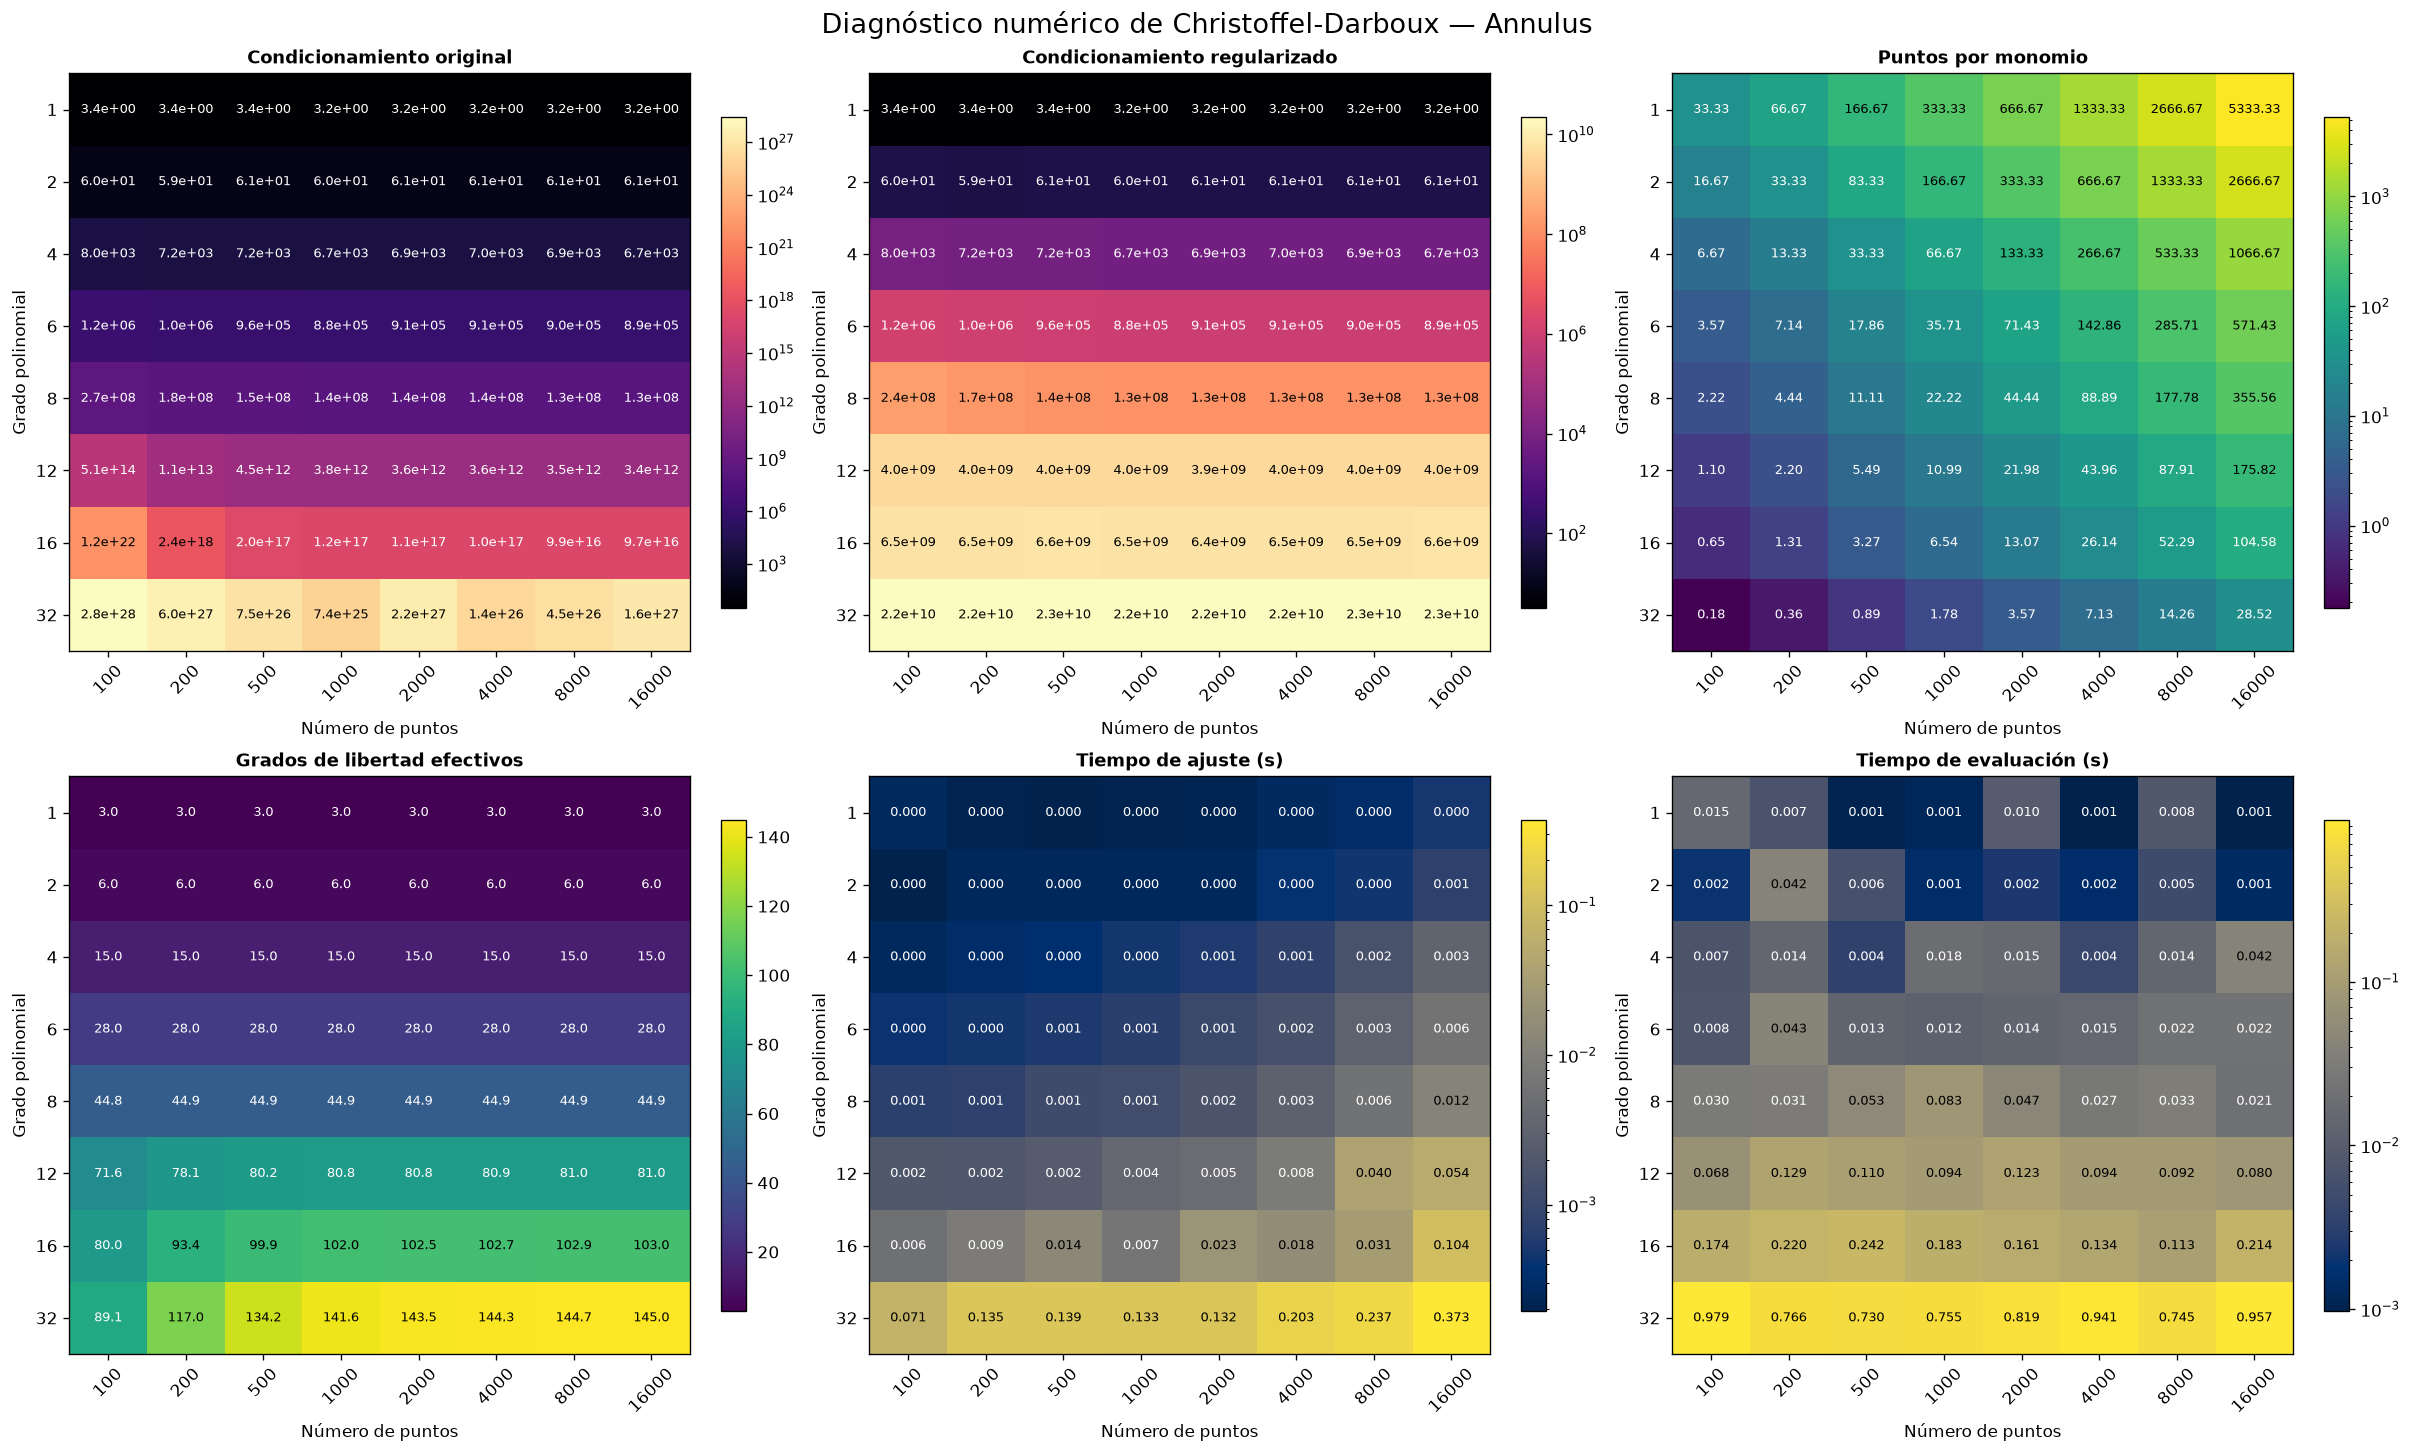

In [10]:
from matplotlib.colors import LogNorm

valid = df[df["status"] == "OK"].copy()

metrics = [
    ("cond_M", "Condicionamiento original", "magma", True),
    ("cond_regularized", "Condicionamiento regularizado", "magma", True),
    ("N_per_basis", "Puntos por monomio", "viridis", True),
    ("effective_dof", "Grados de libertad efectivos", "viridis", False),
    ("fit_time_s", "Tiempo de ajuste (s)", "cividis", True),
    ("eval_time_s", "Tiempo de evaluación (s)", "cividis", True)
]

fig, axs = plt.subplots(
    2, 3,
    figsize=(20, 12),
    constrained_layout=True
)

for ax, (metric, title, cmap, logarithmic) in zip(
    axs.flat, metrics
):

    H = valid.pivot(
        index="degree",
        columns="n_points",
        values=metric
    ).reindex(
        index=DEGREES,
        columns=NPOINTS
    )

    # CORRECCIÓN: crear una copia modificable
    values = H.to_numpy(dtype=float, copy=True)

    values[~np.isfinite(values)] = np.nan

    if logarithmic:
        values[values <= 0] = np.nan

    norm = None

    if logarithmic:

        finite = values[np.isfinite(values)]

        if finite.size and finite.min() < finite.max():

            norm = LogNorm(
                vmin=finite.min(),
                vmax=finite.max()
            )

    im = ax.imshow(
        values,
        cmap=cmap,
        norm=norm,
        aspect="auto"
    )

    # Anotaciones numéricas

    for i in range(len(DEGREES)):
        for j in range(len(NPOINTS)):

            v = values[i, j]

            if not np.isfinite(v):
                label = "—"
                color = "gray"

            else:

                if metric in ["cond_M", "cond_regularized"]:
                    label = f"{v:.1e}"

                elif metric in ["fit_time_s", "eval_time_s"]:
                    label = f"{v:.3f}"

                elif metric == "effective_dof":
                    label = f"{v:.1f}"

                else:
                    label = f"{v:.2f}"

                rgba = im.cmap(im.norm(v))

                luminance = (
                    0.299 * rgba[0]
                    + 0.587 * rgba[1]
                    + 0.114 * rgba[2]
                )

                color = "black" if luminance > 0.5 else "white"

            ax.text(
                j, i,
                label,
                ha="center",
                va="center",
                fontsize=8,
                color=color
            )

    ax.set_xticks(
        range(len(NPOINTS)),
        labels=NPOINTS,
        rotation=45
    )

    ax.set_yticks(
        range(len(DEGREES)),
        labels=DEGREES
    )

    ax.set_xlabel("Número de puntos")
    ax.set_ylabel("Grado polinomial")
    ax.set_title(title, fontweight="bold")

    fig.colorbar(im, ax=ax, shrink=0.85)

fig.suptitle(
    f"Diagnóstico numérico de Christoffel-Darboux — {SHAPE_NAME}",
    fontsize=16
)

save(
    fig,
    f"09_diagnosticos_heatmap_{SHAPE_NAME.lower()}"
)

**3. Métrica opcional de calidad.** Si la forma ofrece una función `contains` o un muestreo denso de referencia, puedes resumir la retícula con IoU, cobertura o error de frontera y generar un heatmap adicional.

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from time import perf_counter

# ============================================================
# 1. CONFIGURACIÓN
# ============================================================

R_INNER = 0.5
R_OUTER = 1.0

N_MC = 30000
MC_SEED = 999

# Dominio de evaluación común
lo = np.array([-1.3, -1.3])
hi = np.array([ 1.3,  1.3])

rng_mc = np.random.default_rng(MC_SEED)

U = rng_mc.uniform(
    lo,
    hi,
    size=(N_MC, 2)
)

# ============================================================
# 2. SOPORTE VERDADERO
# ============================================================

def contains_annulus(X):
    """
    Determina si cada punto pertenece al soporte
    verdadero del anillo.
    """

    r = np.linalg.norm(X, axis=1)

    return (
        (r >= R_INNER)
        & (r <= R_OUTER)
    )


inside_ref = contains_annulus(U)

print("Puntos de evaluación:", len(U))
print("Puntos dentro del soporte:", inside_ref.sum())
print("Puntos fuera del soporte:", (~inside_ref).sum())

# ============================================================
# 3. FUNCIONES DE EVALUACIÓN
# ============================================================

def compute_support_metrics(y_true, y_pred):

    TP = np.sum(y_true & y_pred)
    TN = np.sum(~y_true & ~y_pred)
    FP = np.sum(~y_true & y_pred)
    FN = np.sum(y_true & ~y_pred)

    iou = TP / max(TP + FP + FN, 1)

    precision = TP / max(TP + FP, 1)

    recall = TP / max(TP + FN, 1)

    dice = 2 * TP / max(2 * TP + FP + FN, 1)

    fpr = FP / max(FP + TN, 1)

    area_ratio = (
        y_pred.sum() / max(y_true.sum(), 1)
    )

    area_relative_error = abs(area_ratio - 1)

    return {
        "IoU": iou,
        "Precision": precision,
        "Recall": recall,
        "Dice": dice,
        "FPR": fpr,
        "area_ratio": area_ratio,
        "area_relative_error": area_relative_error,
        "TP": TP,
        "TN": TN,
        "FP": FP,
        "FN": FN
    }


# ============================================================
# 4. BARRIDO EXPERIMENTAL
# ============================================================

rows = []

# Reutilizar X_all de la celda anterior para mantener
# exactamente el mismo muestreo anidado.

for degree in DEGREES:

    for n_points in NPOINTS:

        print(f"Grado={degree} | N={n_points}")

        X = X_all[:n_points]

        try:

            # Ajustar modelo

            start = perf_counter()

            cd = fit_cd(X, degree)

            fit_time = perf_counter() - start

            # Obtener umbral con el mismo criterio
            # que la figura anterior

            threshold = get_threshold(
                cd,
                X,
                THRESHOLD
            )

            # Evaluar puntos independientes

            start = perf_counter()

            q = score_batched(cd, U)

            eval_time = perf_counter() - start

            inside_est = q <= threshold

            # Calcular métricas

            result = compute_support_metrics(
                inside_ref,
                inside_est
            )

            rows.append({
                "shape": SHAPE_NAME,
                "seed": SEED,
                "degree": degree,
                "n_points": n_points,
                "basis_size": cd.basis_size_,
                "threshold": threshold,
                "fit_time_s": fit_time,
                "eval_time_s": eval_time,
                "status": "OK",
                **result
            })

        except Exception as error:

            rows.append({
                "shape": SHAPE_NAME,
                "seed": SEED,
                "degree": degree,
                "n_points": n_points,
                "status": "ERROR",
                "error": str(error)
            })

            print("ERROR:", error)

# ============================================================
# 5. EXPORTACIÓN
# ============================================================

heat = pd.DataFrame(rows)

heat.to_csv(
    OUT / f"09_metricas_soporte_{SHAPE_NAME.lower()}.csv",
    index=False
)

display(heat)

valid_heat = heat[heat["status"] == "OK"].copy()

display(
    valid_heat.pivot(
        index="degree",
        columns="n_points",
        values="IoU"
    ).round(3)
)

Puntos de evaluación: 30000
Puntos dentro del soporte: 10485
Puntos fuera del soporte: 19515
Grado=1 | N=100
Grado=1 | N=200
Grado=1 | N=500
Grado=1 | N=1000
Grado=1 | N=2000
Grado=1 | N=4000
Grado=1 | N=8000
Grado=1 | N=16000
Grado=2 | N=100
Grado=2 | N=200
Grado=2 | N=500
Grado=2 | N=1000
Grado=2 | N=2000
Grado=2 | N=4000
Grado=2 | N=8000
Grado=2 | N=16000
Grado=4 | N=100
Grado=4 | N=200
Grado=4 | N=500
Grado=4 | N=1000
Grado=4 | N=2000
Grado=4 | N=4000
Grado=4 | N=8000
Grado=4 | N=16000
Grado=6 | N=100
Grado=6 | N=200
Grado=6 | N=500
Grado=6 | N=1000
Grado=6 | N=2000
Grado=6 | N=4000
Grado=6 | N=8000
Grado=6 | N=16000
Grado=8 | N=100
Grado=8 | N=200
Grado=8 | N=500
Grado=8 | N=1000
Grado=8 | N=2000
Grado=8 | N=4000
Grado=8 | N=8000
Grado=8 | N=16000
Grado=12 | N=100
Grado=12 | N=200
Grado=12 | N=500
Grado=12 | N=1000
Grado=12 | N=2000
Grado=12 | N=4000
Grado=12 | N=8000
Grado=12 | N=16000
Grado=16 | N=100
Grado=16 | N=200
Grado=16 | N=500
Grado=16 | N=1000
Grado=16 | N=2000
Grado=16

,shape,seed,degree,n_points,basis_size,threshold,fit_time_s,eval_time_s,status,IoU,Precision,Recall,Dice,FPR,area_ratio,area_relative_error,TP,TN,FP,FN
0,Annulus,100,1,100,3,4.096819,0.000262,0.089782,OK,0.679654,0.721302,0.921698,0.809279,0.191340,1.277825,0.277825,9664,15781,3734,821
1,Annulus,100,1,200,3,4.099963,0.000222,0.057492,OK,0.698560,0.731561,0.939342,0.822532,0.185191,1.284025,0.284025,9849,15901,3614,636
2,Annulus,100,1,500,3,4.118666,0.000219,0.006075,OK,0.695814,0.726158,0.943348,0.820626,0.191135,1.299094,0.299094,9891,15785,3730,594
3,Annulus,100,1,1000,3,4.054230,0.000199,0.006686,OK,0.706517,0.738056,0.942966,0.828022,0.179810,1.277635,0.277635,9887,16006,3509,598
4,Annulus,100,1,2000,3,4.046716,0.000207,0.011220,OK,0.713530,0.740085,0.952122,0.832819,0.179657,1.286505,0.286505,9983,16009,3506,502
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
59,Annulus,100,32,1000,561,428.262768,0.113538,1.123738,OK,0.888807,0.959746,0.923224,0.941131,0.020805,0.961946,0.038054,9680,19109,406,805
60,Annulus,100,32,2000,561,389.138393,0.147332,1.202860,OK,0.912201,0.965070,0.943348,0.954085,0.018345,0.977492,0.022508,9891,19157,358,594
61,Annulus,100,32,4000,561,381.770857,0.157933,1.128132,OK,0.911103,0.964938,0.942299,0.953484,0.018396,0.976538,0.023462,9880,19156,359,605
62,Annulus,100,32,8000,561,377.831883,0.321298,1.745564,OK,0.913344,0.963661,0.945923,0.954710,0.019165,0.981593,0.018407,9918,19141,374,567


n_points,100,200,500,1000,2000,4000,8000,16000
degree,,,,,,,,
1,0.680,0.699,0.696,0.707,0.714,0.710,0.709,0.712
2,0.664,0.702,0.699,0.711,0.712,0.711,0.709,0.712
4,0.782,0.782,0.800,0.807,0.817,0.811,0.808,0.807
6,0.843,0.848,0.871,0.880,0.888,0.882,0.879,0.880
8,0.783,0.859,0.905,0.921,0.926,0.919,0.917,0.918
12,0.253,0.754,0.896,0.927,0.933,0.928,0.927,0.927
16,0.147,0.663,0.875,0.918,0.928,0.925,0.925,0.924
32,0.070,0.511,0.827,0.889,0.912,0.911,0.913,0.914


**4. Variante 3D.** La misma lógica puede repetirse sobre una esfera, toro o superficie de point-field. Para la tesis suele funcionar mejor mostrar la retícula 2D para explicar el fenómeno y después una figura 3D-resumen con cobertura/franja, como ya haces en el documento.

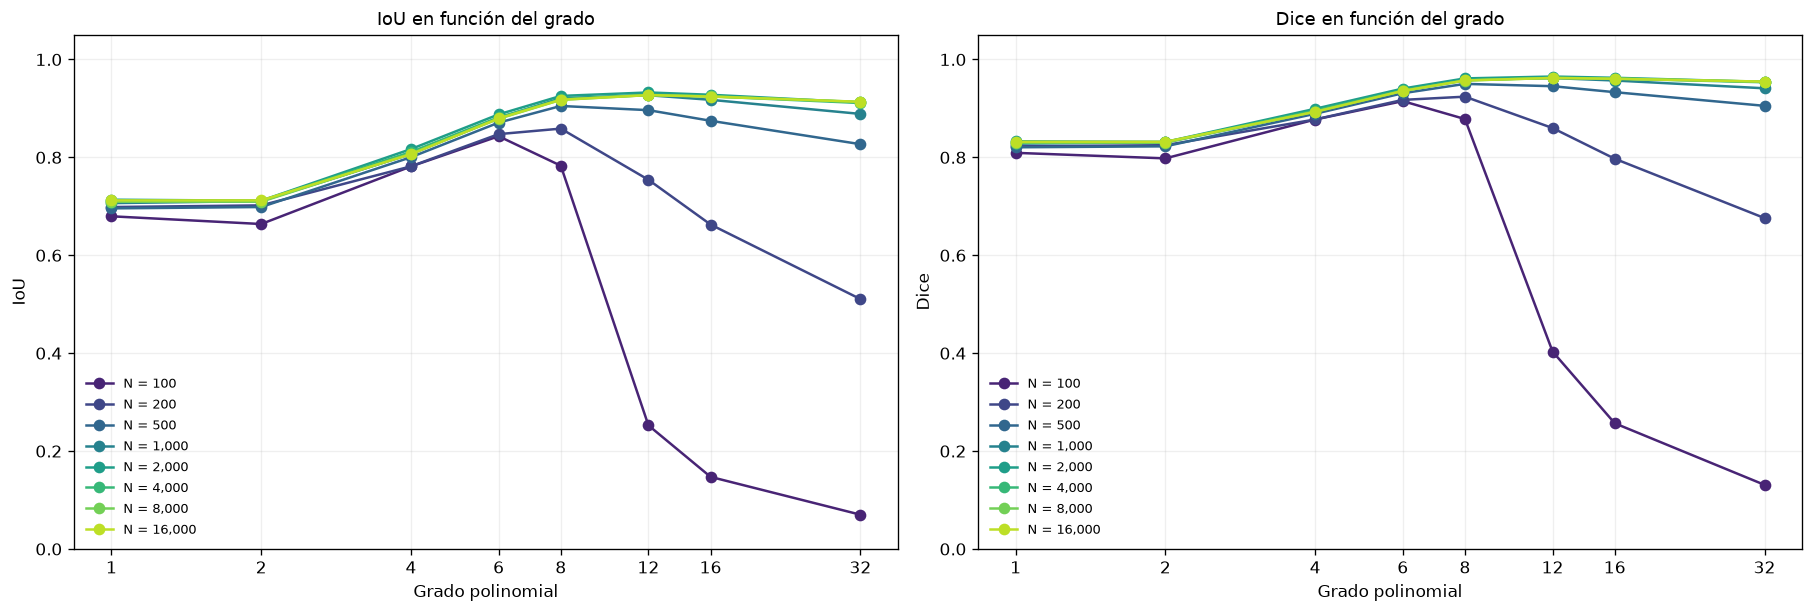

In [12]:
fig, axs = plt.subplots(
    1, 2,
    figsize=(15, 5),
    constrained_layout=True
)

colors = plt.cm.viridis(
    np.linspace(0.1, 0.9, len(NPOINTS))
)

for color, n_points in zip(colors, NPOINTS):

    sub = valid_heat[
        valid_heat["n_points"] == n_points
    ].sort_values("degree")

    axs[0].plot(
        sub["degree"],
        sub["IoU"],
        marker="o",
        color=color,
        label=f"N = {n_points:,}"
    )

    axs[1].plot(
        sub["degree"],
        sub["Dice"],
        marker="o",
        color=color,
        label=f"N = {n_points:,}"
    )

for ax in axs:

    ax.set_xscale("log", base=2)
    ax.set_xticks(DEGREES)
    ax.set_xticklabels(DEGREES)

    ax.set_xlabel("Grado polinomial")
    ax.set_ylim(0, 1.05)
    ax.grid(alpha=0.2)
    ax.legend(frameon=False, fontsize=8)

axs[0].set_title("IoU en función del grado")
axs[0].set_ylabel("IoU")

axs[1].set_title("Dice en función del grado")
axs[1].set_ylabel("Dice")

save(
    fig,
    f"09_curvas_desempeno_{SHAPE_NAME.lower()}"
)